In [6]:
import os
import json
import cv2
import matplotlib.pyplot as plt

# 1. Cek isi direktori input Kaggle untuk memastikan nama folder persisnya
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)
    if len(filenames) > 0:
        print("  Contoh file:", filenames[:3])


/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/solesensei
/kaggle/input/datasets/solesensei/solesensei_bdd100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test
  Contoh file: ['cb2fe290-8786cd14.jpg', 'cb8b28d3-ab96a5fc.jpg', 'cbed3fd1-314723c8.jpg']
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test/testA
  Contoh file: ['cb1f05ca-28b96d3e.jpg', 'cb2382b5-9cc2c304.jpg', 'cb25355a-3ac85fc1.jpg']
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test/testB
  Contoh file: ['cb2512c2-c2d1b0f2.jpg', 'cb253f3b-b54796d8.jpg', 'cb25d527-e041ee3a.jpg']
/kaggle/input/datasets/solesensei/solesensei_b

In [7]:
import os
import json
import cv2
import matplotlib.pyplot as plt

# 1. Cari lokasi pasti file JSON label train
base_dir = '/kaggle/input/datasets/solesensei/solesensei_bdd100k'
json_path = None

for root, dirs, files in os.walk(base_dir):
    for f in files:
        if 'labels_images_train.json' in f:
            json_path = os.path.join(root, f)
            break

print("File label ditemukan di:", json_path)

# 2. Baca isi file JSON (ini butuh waktu sekitar 5-10 detik karena filenya besar)
with open(json_path, 'r') as f:
    labels_data = json.load(f)

print(f"Total data train berlabel: {len(labels_data)} gambar")
print("\nContoh struktur 1 data (gambar pertama):")
print(json.dumps(labels_data[0], indent=2)[:800]) # Menampilkan 800 karakter pertama


File label ditemukan di: /kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k_labels_release/bdd100k/labels/bdd100k_labels_images_train.json
Total data train berlabel: 69863 gambar

Contoh struktur 1 data (gambar pertama):
{
  "name": "0000f77c-6257be58.jpg",
  "attributes": {
    "weather": "clear",
    "scene": "city street",
    "timeofday": "daytime"
  },
  "timestamp": 10000,
  "labels": [
    {
      "category": "traffic light",
      "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "green"
      },
      "manualShape": true,
      "manualAttributes": true,
      "box2d": {
        "x1": 1125.902264,
        "y1": 133.184488,
        "x2": 1156.978645,
        "y2": 210.875445
      },
      "id": 0
    },
    {
      "category": "traffic light",
      "attributes": {
        "occluded": false,
        "truncated": false,
        "trafficLightColor": "green"
      },
      "manualShape": true,
      "manualAttributes": tr

Mengindeks lokasi semua gambar (butuh ~10 detik)...
Total file .jpg terindeks: 100000


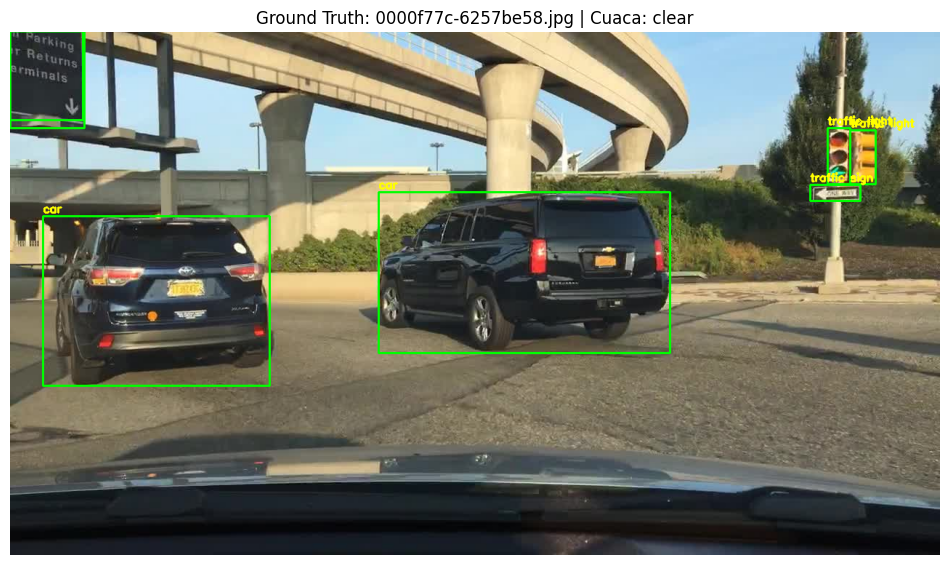

In [8]:
import shutil
import random
from tqdm import tqdm

# 1. Mapping 10 kelas utama BDD100K ke angka (0-9) untuk YOLO
CLASSES = [
    "car", "bus", "truck", "train", "motor",
    "bike", "person", "rider", "traffic light", "traffic sign"
]
class_to_id = {cls: i for i, cls in enumerate(CLASSES)}

# 2. Cari path file gambar berdasarkan nama file (karena gambar tersebar di folder trainA/trainB/val)
img_root = '/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k'
print("Mengindeks lokasi semua gambar (butuh ~10 detik)...")
img_path_map = {}
for root, _, files in os.walk(img_root):
    for f in files:
        if f.endswith('.jpg'):
            img_path_map[f] = os.path.join(root, f)

print(f"Total file .jpg terindeks: {len(img_path_map)}")

# 3. Visualisasi sampel pertama untuk verifikasi (penting untuk dokumentasi GitHub!)
sample = labels_data[0]
sample_img_path = img_path_map[sample['name']]
img = cv2.imread(sample_img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for obj in sample.get('labels', []):
    if 'box2d' in obj and obj['category'] in class_to_id:
        box = obj['box2d']
        x1, y1, x2, y2 = int(box['x1']), int(box['y1']), int(box['x2']), int(box['y2'])
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, obj['category'], (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2)

plt.figure(figsize=(12, 7))
plt.imshow(img)
plt.title(f"Ground Truth: {sample['name']} | Cuaca: {sample['attributes']['weather']}")
plt.axis('off')
plt.show()


In [9]:
import os
import json
import shutil
import random
from tqdm import tqdm

# 1. Buat struktur folder standar YOLO di direktori kerja Kaggle (/kaggle/working)
yolo_base = '/kaggle/working/bdd_yolo'
for split in ['train', 'val']:
    os.makedirs(f'{yolo_base}/images/{split}', exist_ok=True)
    os.makedirs(f'{yolo_base}/labels/{split}', exist_ok=True)

# 2. Load file JSON validation juga
val_json_path = json_path.replace('train.json', 'val.json')
with open(val_json_path, 'r') as f:
    val_labels_data = json.load(f)

# Fungsi konversi koordinat BDD (x1, y1, x2, y2) -> YOLO (x_center, y_center, width, height ternormalisasi)
def convert_to_yolo(data_list, split_name, max_samples):
    random.seed(42) # Agar hasil sampling konsisten (reproducible)
    sampled_data = random.sample(data_list, min(max_samples, len(data_list)))
    
    IMG_W, IMG_H = 1280.0, 720.0 # Resolusi standar gambar BDD100K
    converted_count = 0
    
    for item in tqdm(sampled_data, desc=f"Memproses {split_name}"):
        img_name = item['name']
        if img_name not in img_path_map:
            continue
            
        yolo_lines = []
        for obj in item.get('labels', []):
            if 'box2d' in obj and obj['category'] in class_to_id:
                cls_id = class_to_id[obj['category']]
                box = obj['box2d']
                
                # Hitung titik tengah dan lebar/tinggi ternormalisasi (0 - 1)
                x_center = ((box['x1'] + box['x2']) / 2.0) / IMG_W
                y_center = ((box['y1'] + box['y2']) / 2.0) / IMG_H
                width = (box['x2'] - box['x1']) / IMG_W
                height = (box['y2'] - box['y1']) / IMG_H
                
                # Pastikan nilai valid di antara 0 dan 1
                if width > 0 and height > 0:
                    yolo_lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")
        
        # Hanya simpan gambar yang memiliki minimal 1 objek berlabel
        if len(yolo_lines) > 0:
            # Copy gambar ke folder YOLO
            shutil.copy(img_path_map[img_name], f"{yolo_base}/images/{split_name}/{img_name}")
            # Tulis file label .txt
            txt_name = img_name.replace('.jpg', '.txt')
            with open(f"{yolo_base}/labels/{split_name}/{txt_name}", 'w') as out_f:
                out_f.write('\n'.join(yolo_lines))
            converted_count += 1
            
    print(f"Selesai {split_name}: {converted_count} gambar & label siap.")

# Jalankan konversi untuk 2.500 train dan 500 val
convert_to_yolo(labels_data, 'train', 2500)
convert_to_yolo(val_labels_data, 'val', 500)

# 3. Buat file konfigurasi dataset (data.yaml) yang wajib ada untuk YOLO
yaml_content = f"""path: {yolo_base}
train: images/train
val: images/val

nc: {len(CLASSES)}
names: {CLASSES}
"""

with open('/kaggle/working/bdd100k.yaml', 'w') as f:
    f.write(yaml_content)

print("\nFile konfigurasi bdd100k.yaml berhasil dibuat!")


Memproses train: 100%|██████████| 2500/2500 [00:06<00:00, 378.28it/s]


Selesai train: 2500 gambar & label siap.


Memproses val: 100%|██████████| 500/500 [00:01<00:00, 422.43it/s]

Selesai val: 500 gambar & label siap.

File konfigurasi bdd100k.yaml berhasil dibuat!


In [10]:
# Instal library ultralytics (YOLOv8)
!pip install -q ultralytics

from ultralytics import YOLO

# Gunakan model YOLOv8s (Small) - keseimbangan terbaik antara kecepatan dan akurasi
model = YOLO('yolov8s.pt')

# Mulai proses training!
results = model.train(
    data='/kaggle/working/bdd100k.yaml',
    epochs=15,          # 15 putaran belajar (cukup untuk melihat hasil tajam dalam ~12 menit)
    imgsz=640,          # Ukuran gambar standar untuk YOLO
    batch=16,           # Jumlah gambar yang diproses bersamaan di GPU
    project='/kaggle/working/runs',
    name='bdd100k_yolov8s',
    device=0            # Gunakan GPU
)


Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/bdd100k.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=bdd100k_yolov8s-2, nbs=64, nms=None, opset=None, optimize=F

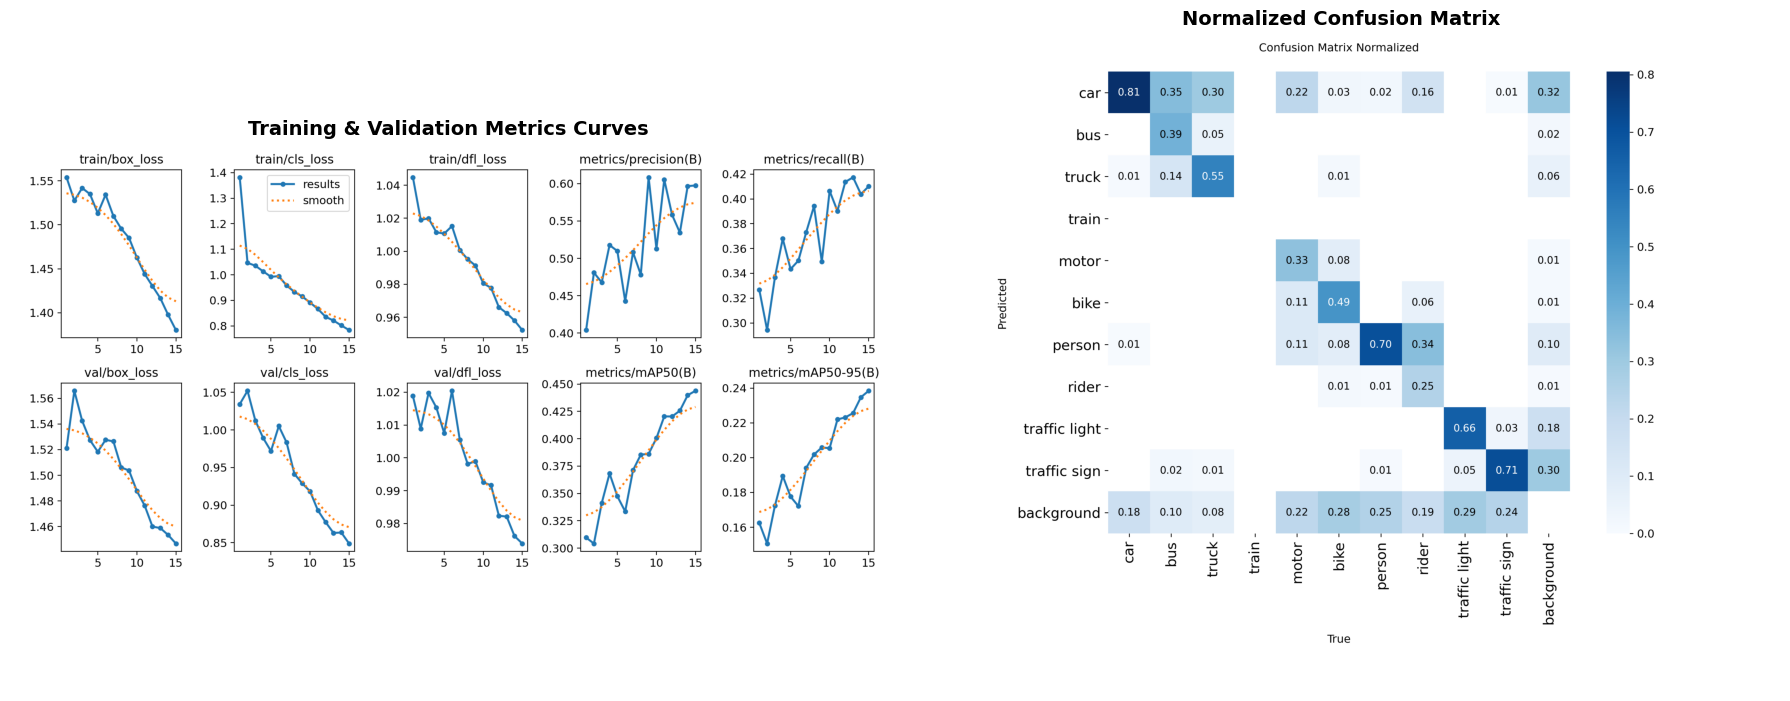


0: 384x640 5 cars, 4 traffic lights, 1 traffic sign, 14.4ms
1: 384x640 8 cars, 1 bike, 4 persons, 1 traffic light, 1 traffic sign, 14.4ms
2: 384x640 1 car, 8 traffic signs, 14.4ms
3: 384x640 10 cars, 2 traffic lights, 4 traffic signs, 14.4ms
Speed: 1.5ms preprocess, 14.4ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)


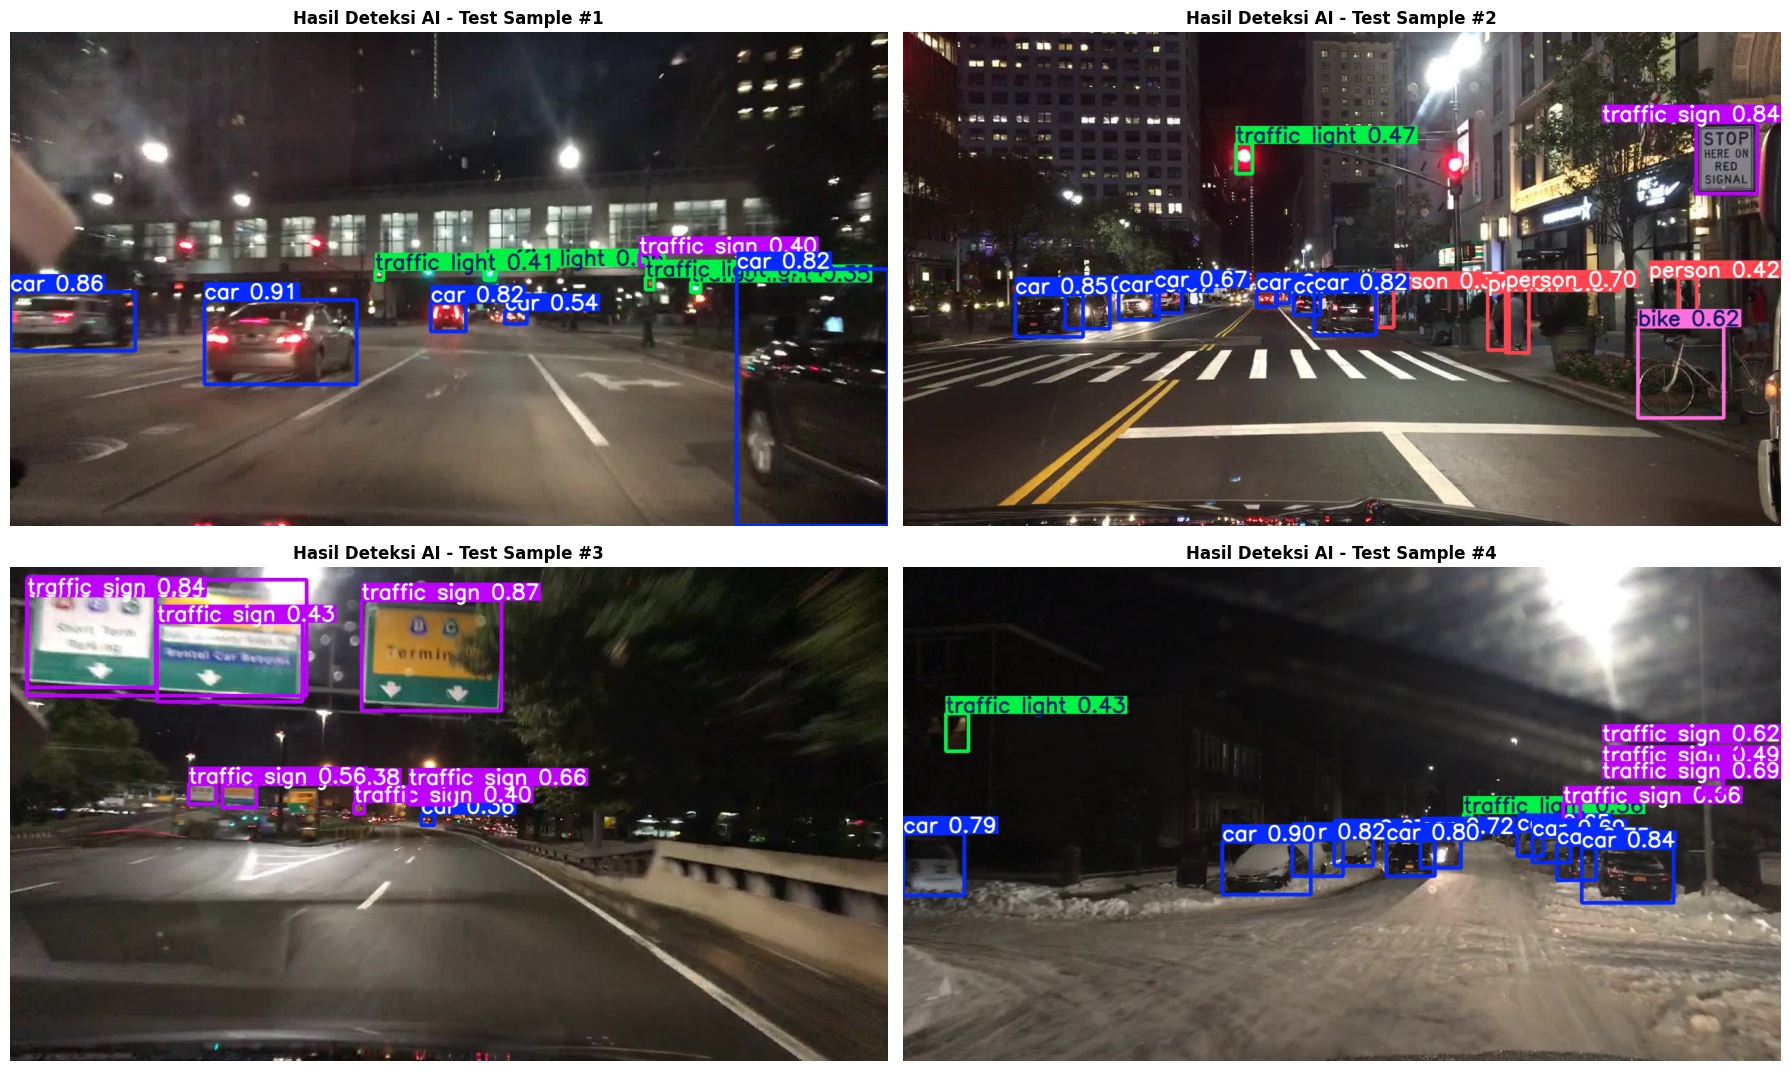

Selesai! Kedua gambar portofolio siap diunduh.


In [12]:
import glob
import random
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load model terbaik dari folder bdd100k_yolov8s-2
run_dir = '/kaggle/working/runs/bdd100k_yolov8s-2'
best_model = YOLO(f'{run_dir}/weights/best.pt')

# 2. Gabungkan Grafik Training Curves & Confusion Matrix untuk dokumentasi GitHub
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

results_img = cv2.cvtColor(cv2.imread(f'{run_dir}/results.png'), cv2.COLOR_BGR2RGB)
cm_img = cv2.cvtColor(cv2.imread(f'{run_dir}/confusion_matrix_normalized.png'), cv2.COLOR_BGR2RGB)

axes[0].imshow(results_img)
axes[0].set_title("Training & Validation Metrics Curves", fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cm_img)
axes[1].set_title("Normalized Confusion Matrix", fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/portfolio_evaluation.png', dpi=150)
plt.show()

# 3. Uji Coba (Inference) pada 4 gambar baru dari folder TEST
test_images = glob.glob('/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/test/*.jpg')
random.seed(101)
sample_tests = random.sample(test_images, 4)

predictions = best_model.predict(sample_tests, conf=0.35, save=False)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
axes = axes.flatten()

for i, pred in enumerate(predictions):
    annotated_img = cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB)
    axes[i].imshow(annotated_img)
    axes[i].set_title(f"Hasil Deteksi AI - Test Sample #{i+1}", fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/portfolio_predictions.png', dpi=150)
plt.show()

print("Selesai! Kedua gambar portofolio siap diunduh.")
